In [1]:
import numpy as np
from matplotlib import pyplot as plt
from numba import njit, prange

## Unique Points

This portion of the notebook generates some RabitQ 2 bit grids, i.e. [0, 1, 2, 3].

It then shifts them by -1.5 in each dimension, as per the paper.

Here, we measure how many 'unique points' (i.e. those without another point which maps to the same point on the hypersphere) on the hypersphere this mapping results in as d increases

In [2]:
vals = [0, 1, 2, 3]
MAX_VAL = 3

In [3]:
def make_grid(dimensions):
    grids= []
    current = [0 for _ in range(dimensions)]
    
    return np.array(extend_grid(grids, current)) - 1.5
    
def extend_grid(grids, current):
    
    finished = False
    
    
    while not finished:
        grids.append(current)
        
        if np.any(current != MAX_VAL):
            current = get_next_grid(current)                
        else:
            finished = True
            
    return grids
        
def get_next_grid(vec):
   index = 0
   finished = False
   
   new_vec = np.copy(vec)
   
   while not finished:
        new_vec[index] += 1
        
        if new_vec[index] == MAX_VAL + 1 and index < len(new_vec):
            new_vec[index] = 0
        else:
            return new_vec
            
        index += 1
    

In [4]:
print(make_grid(2))

[[-1.5 -1.5]
 [-0.5 -1.5]
 [ 0.5 -1.5]
 [ 1.5 -1.5]
 [-1.5 -0.5]
 [-0.5 -0.5]
 [ 0.5 -0.5]
 [ 1.5 -0.5]
 [-1.5  0.5]
 [-0.5  0.5]
 [ 0.5  0.5]
 [ 1.5  0.5]
 [-1.5  1.5]
 [-0.5  1.5]
 [ 0.5  1.5]
 [ 1.5  1.5]]


In [5]:


def count_unique_rows(a, rtol=1e-5, atol=1e-8):
    reps = []

    for row in np.asarray(a):
        if not reps or not np.any(
            np.all(np.isclose(reps, row, rtol=rtol, atol=atol), axis=1)
        ):
            reps.append(row)

    return len(reps)

def count_unique(n):    
    grid = make_grid(n)
    normalised_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)
    return count_unique_rows(normalised_grid)

def frac_unique(n):
    return count_unique(n) / (4 ** n)

In [6]:
frac_unique(3)

0.875

In [7]:
ds = [i for i in range(2, 6)]
fracs = [frac_unique(d) for d in ds]

Text(0, 0.5, 'Fraction Unique')

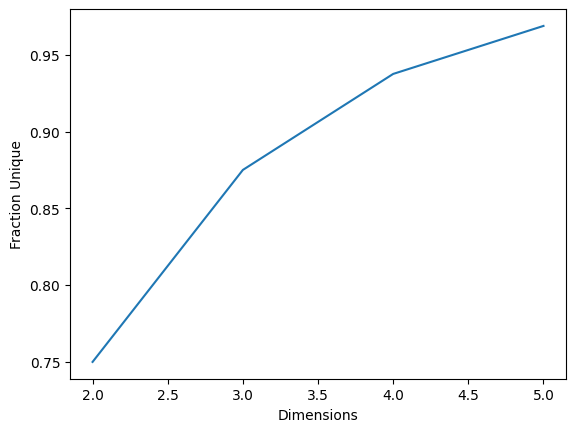

In [8]:
plt.plot(ds, fracs)
plt.xlabel("Dimensions")
plt.ylabel("Fraction Unique")

## Cell Sizes
We know that EVPs have equally sized voranoi cells.

We measure the voranoi cell sizes of codebook vectors via Monte-Carlo sampling here.

In [9]:
import numpy as np
from numba import njit, prange, get_num_threads, get_thread_id
from numba_progress import ProgressBar


@njit(
    parallel=True,
    boundscheck=False,
    nogil=True,
)
def monte_carlo(grid, progress_proxy, reps=1_000):
    n_grid = grid.shape[0]
    dim = grid.shape[1]

    n_threads = get_num_threads()

    # Each thread gets its own histogram to avoid race conditions.
    thread_bins = np.zeros(
        (n_threads, n_grid),
        dtype=np.int64,
    )

    for i in prange(reps):
        tid = get_thread_id()

        # Random direction.
        #
        # No need to normalize it: multiplying all dot products
        # by the same positive factor doesn't affect argmax.
        point = np.random.normal(0.0, 1.0, dim)

        
        best_id = 0
        best_score = -np.inf

        for k in range(n_grid):
            score = 0.0

            for j in range(dim):
                score += grid[k, j] * point[j]

            if score > best_score:
                best_score = score
                best_id = k

        thread_bins[tid, best_id] += 1

        progress_proxy.update(1)

    # Combine the per-thread histograms.
    monte_carlo_bins = np.zeros(n_grid, dtype=np.int64)

    for t in range(n_threads):
        for k in range(n_grid):
            monte_carlo_bins[k] += thread_bins[t, k]

    return monte_carlo_bins

In [10]:
reps = 10_000_000

dim = 4
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)

with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

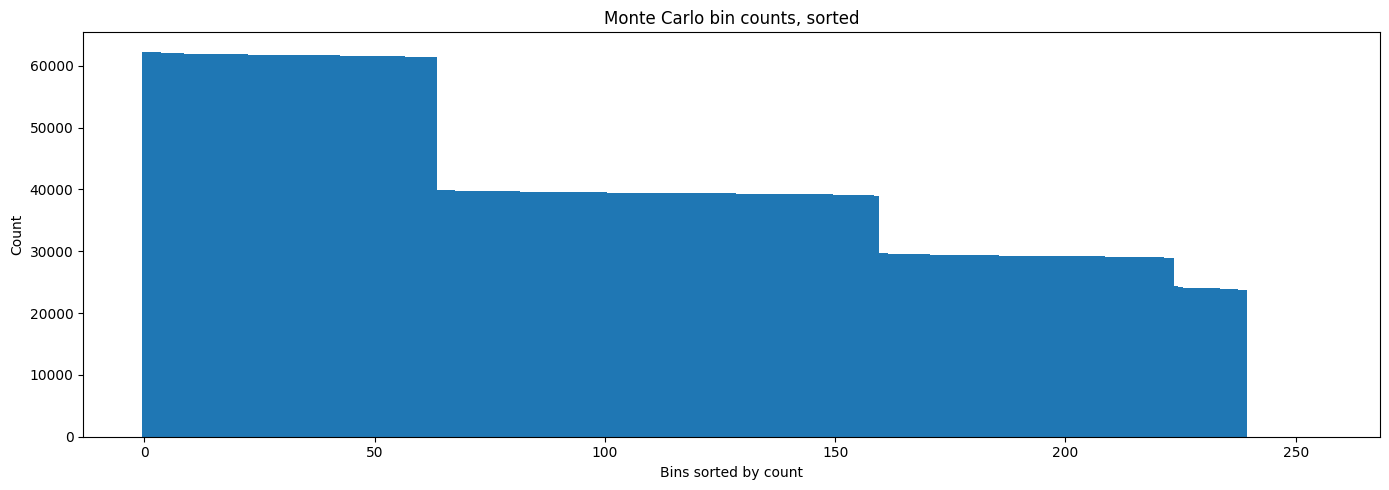

In [11]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [12]:
reps = 10_000_000

dim = 6
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)

with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

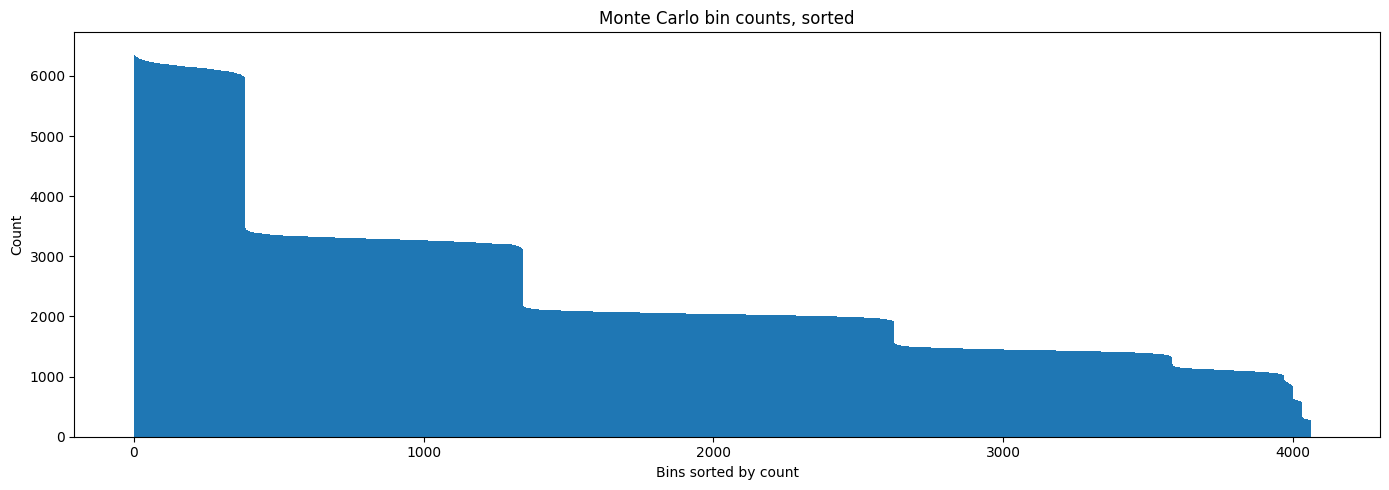

In [13]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [14]:
reps = 10_000_000

dim = 8
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)


with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

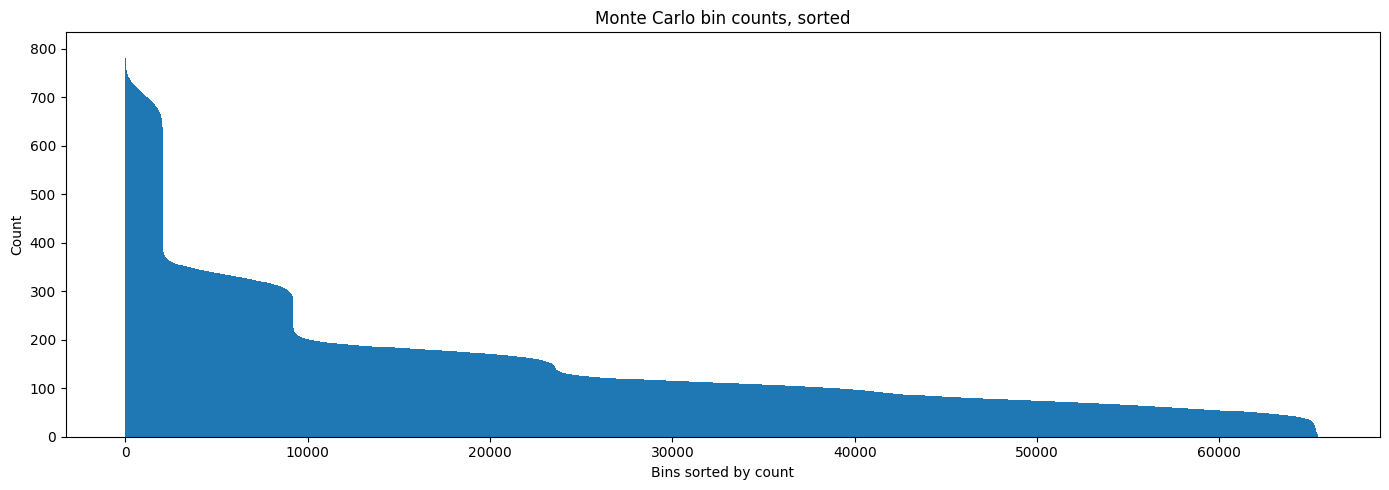

In [15]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()

In [16]:
reps = 10_000_000

dim = 10
grid = make_grid(dim)

# Use this if you're comparing directions / angular closeness
normed_grid = grid / np.linalg.norm(grid, axis=1, keepdims=True)


with ProgressBar(total=reps) as progress:
    bins = monte_carlo(
        normed_grid,
        progress,
        reps,
    )

  0%|          | 0/10000000 [00:00<?, ?it/s]

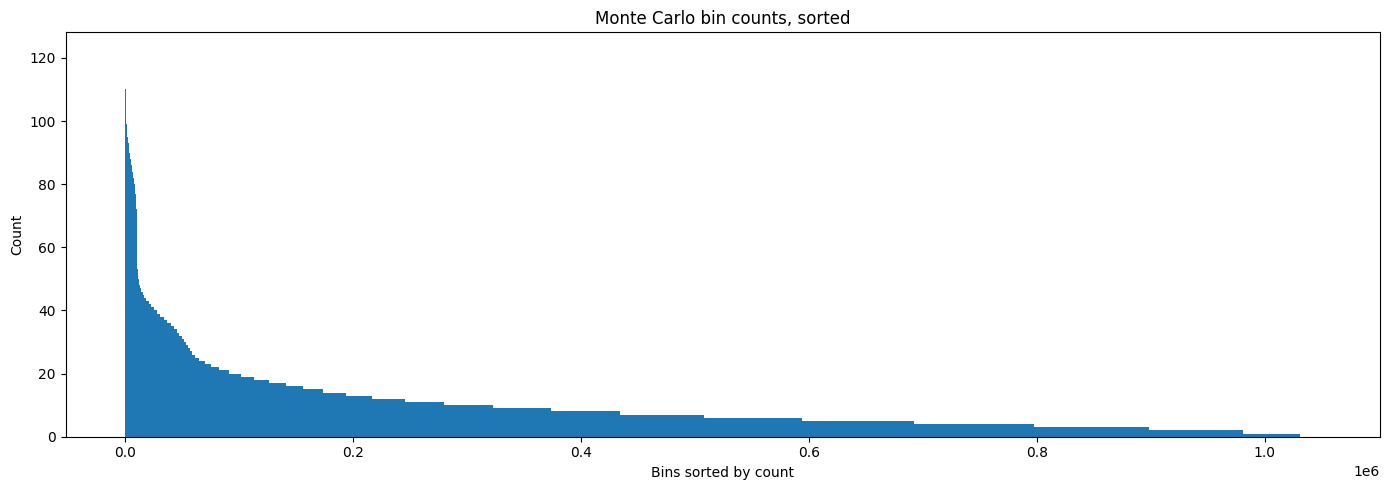

In [17]:
import matplotlib.pyplot as plt
import numpy as np

sorted_bins = np.sort(bins)[::-1]  # largest to smallest

fig, ax = plt.subplots(figsize=(14, 5))

x = np.arange(len(sorted_bins))
ax.bar(x, sorted_bins, width=1.0)

ax.set_xlabel("Bins sorted by count")
ax.set_ylabel("Count")
ax.set_title("Monte Carlo bin counts, sorted")

plt.tight_layout()
plt.show()